## Video 2.3

In [31]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import utils

In [32]:
FEATURES_2D = ["x1", "x2"]

#### accuracy can reward a useless model
High accuracy can hide poor minority-class performance when classes are imbalanced.

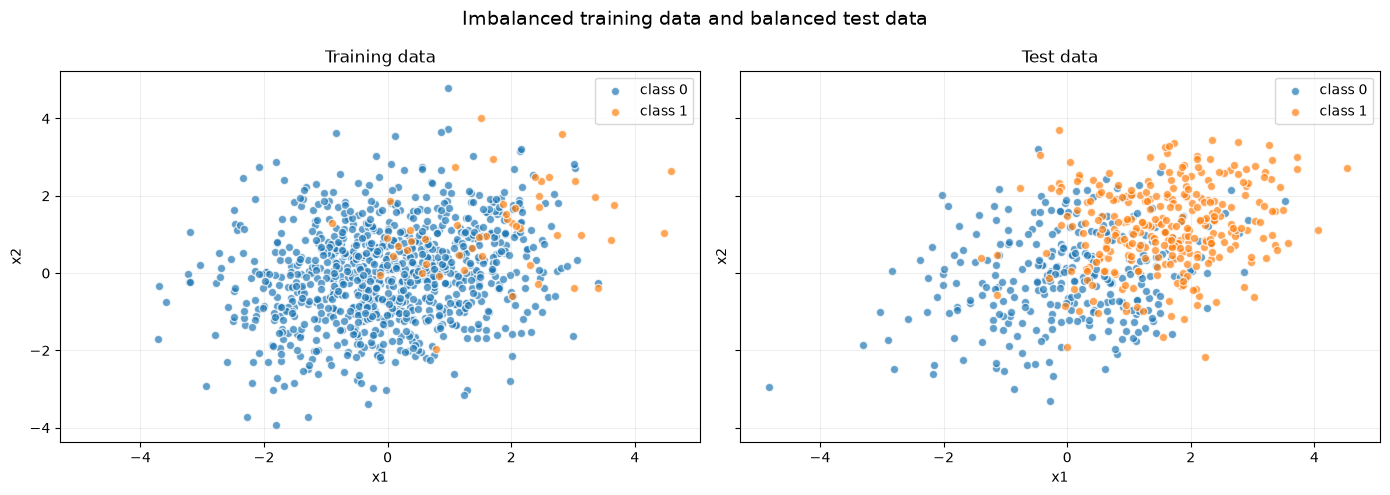

In [33]:
imbalanced_train = pd.read_csv("data5_imbalanced_train.csv")
imbalanced_test = pd.read_csv("data5_imbalanced_test.csv")

utils.display_points(imbalanced_train, "Imbalanced training data and balanced test data", imbalanced_test)

In [34]:
print("  Class proportions ")
print("--------------------------------")

print("TRAINING")
display(imbalanced_train["class"].value_counts(normalize=True).sort_index().rename("proportion"))
print("--------------------------------")
print("TEST")
display(imbalanced_test["class"].value_counts(normalize=True).sort_index().rename("proportion"))

  Class proportions 
--------------------------------
TRAINING


class
0    0.95
1    0.05
Name: proportion, dtype: float64

--------------------------------
TEST


class
0    0.5
1    0.5
Name: proportion, dtype: float64

In [35]:
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression

In [36]:
imbalance_models = {
    "Always no (class 0)": DummyClassifier(strategy="constant", constant=0),
    "Logistic regression": LogisticRegression(),
    "Class-balanced logistic": LogisticRegression(class_weight="balanced"),
}

In [37]:
rows = []
for name, model in imbalance_models.items():
    model.fit(imbalanced_train[FEATURES_2D], imbalanced_train["class"])
    for split_name, data in [("train", imbalanced_train), ("test", imbalanced_test)]:
        predictions = model.predict(data[FEATURES_2D])
        rows.append({
            "model": name,
            "split": split_name,
            "accuracy": utils.accuracy_score(data["class"], predictions),
            "balanced accuracy": utils.balanced_accuracy_score(data["class"], predictions),
            "positive recall": utils.recall_score(data["class"], predictions, zero_division=0),
        })

In [38]:
results = pd.DataFrame(rows)
results.set_index(["model", "split"]).round(3)

accuracy  balanced accuracy  positive recall
model                   split                                              
Always no (class 0)     train     0.950              0.500            0.000
                        test      0.500              0.500            0.000
Logistic regression     train     0.955              0.569            0.140
                        test      0.538              0.538            0.080
Class-balanced logistic train     0.782              0.753            0.720
                        test      0.807              0.807            0.817

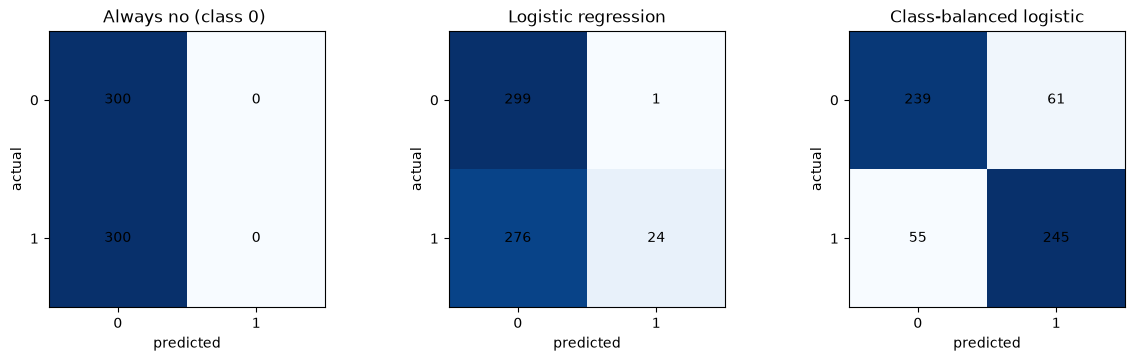

In [39]:
def plot_test_confusions(models):
    _, axes = plt.subplots(1, len(models), figsize=(12, 3.5), constrained_layout=True)
    for ax, (name, model) in zip(axes, models.items()):
        cm = utils.confusion_matrix(imbalanced_test["class"], model.predict(imbalanced_test[FEATURES_2D]))
        ax.imshow(cm, cmap="Blues")
        ax.set(title=name, xlabel="predicted", ylabel="actual", xticks=[0, 1], yticks=[0, 1])
        for row in range(2):
            for column in range(2):
                ax.text(column, row, cm[row, column], ha="center", va="center")
    plt.show()


plot_test_confusions(imbalance_models)

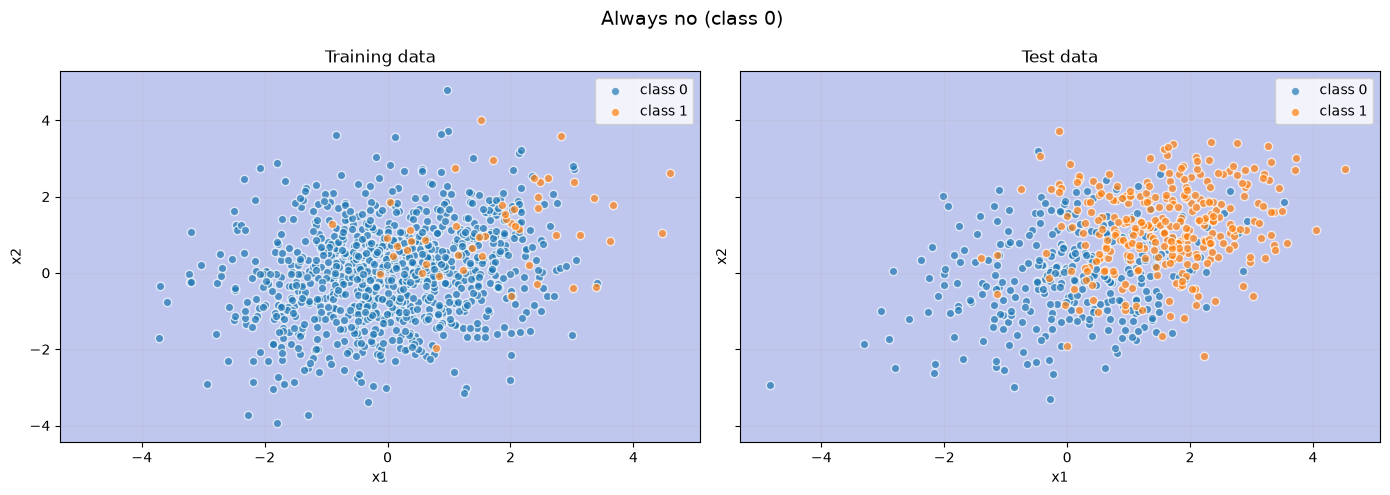

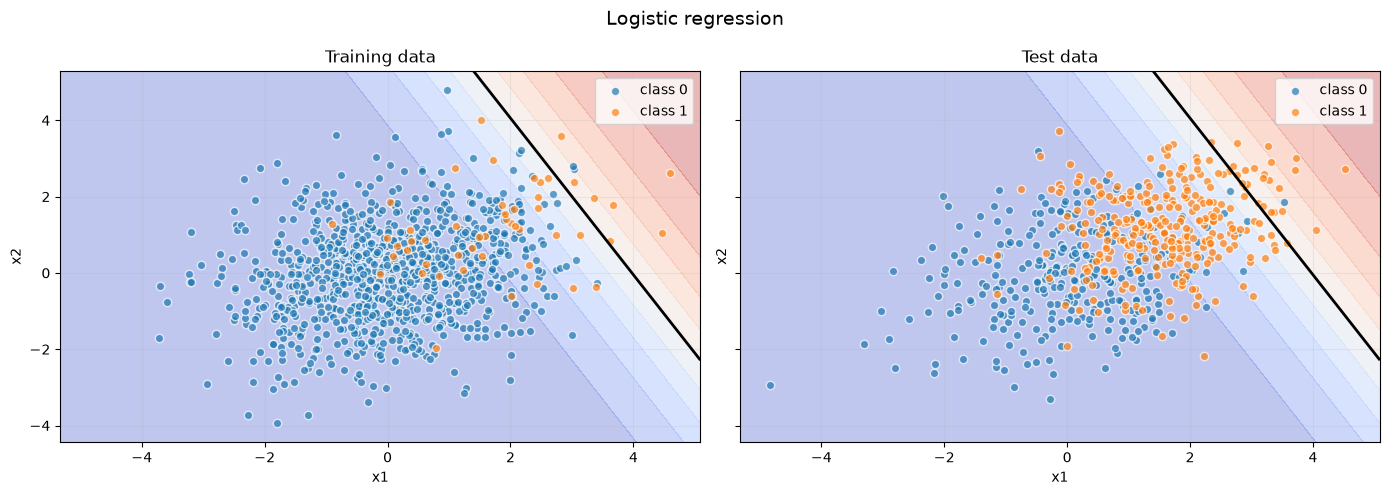

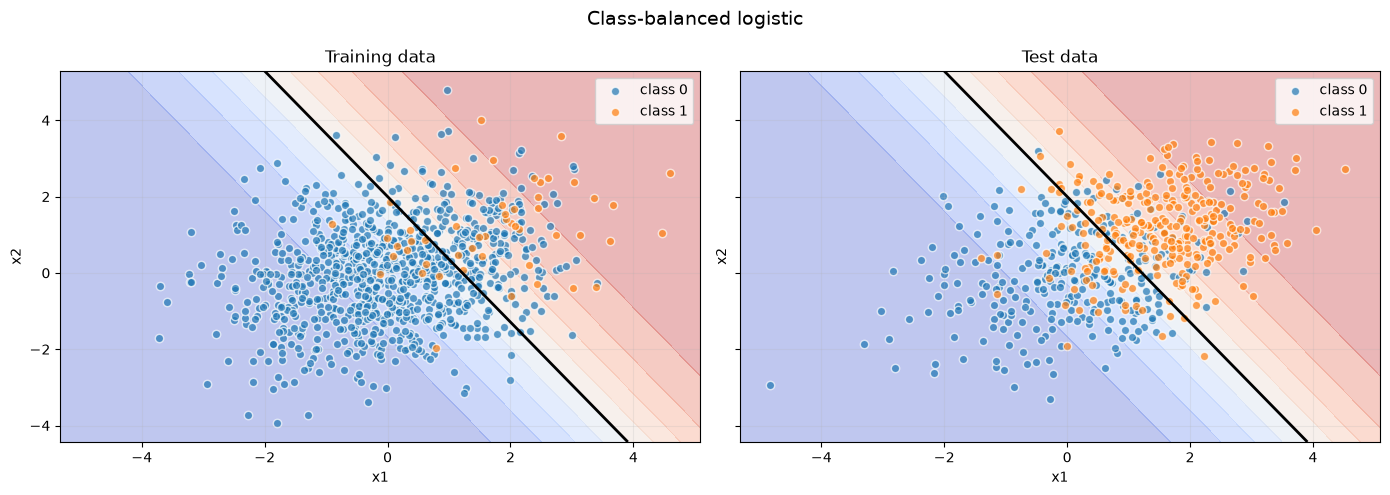

In [40]:
for name, model in imbalance_models.items():
    utils.display_classifications(
        model, imbalanced_train,
        f"{name}",
        test=imbalanced_test,
    )